# Week 4: Variational free energy (JAX)

The NumPy notebook computes Week 4's numbers with hand-written derivatives. This one
does what automatic differentiation or many simultaneous runs make easy: it checks
Fisher's identity and the Laplace curvature with `jax.grad` and `jax.hessian`, maps
sequential coordinate ascent over forty thousand starting beliefs with `jax.vmap`,
and solves the Exponential and Gamma E-steps of Lesson 5 on all 500 trials at once,
with the hand-derived gradients checked against automatic ones.

### AI use

This course notebook was developed with substantial assistance from Claude
(Anthropic) and Gemini (Google), and revised with Codex (OpenAI), under Jonathan
Shock's direction. AI contributed to explanations and code. See [AI use and attribution](https://shocklab.github.io/Active-Inference-course/ai-use.html)
for the review process and its limits.

In [1]:
import jax
jax.config.update('jax_enable_x64', True)
import jax.numpy as jnp
from jax.scipy.special import erf as jerf, gammaln, digamma
import numpy as np
import matplotlib.pyplot as plt
from math import cos, log, pi, sqrt
from time import perf_counter

COL = {'accent': '#0f5f57', 'clay': '#9c4d2f', 'blue': '#2c5f8a', 'gold': '#8a6d1f', 'violet': '#6b4a8a'}

def check(name, got, key, rtol):
    """Compare a result with the value printed in the lesson (from values.py)."""
    want = EXPECTED[key]
    err = abs(got - want) / max(1.0, abs(want))
    status = "ok" if err <= rtol else "MISMATCH"
    print(f"{status:8s} {name:38s} {got: .10g}   lesson {want: .10g}")
    assert err <= rtol, (name, got, want)

## 1. Derivatives of free energies

Fisher's identity (Lesson 4): with $Q$ held at the exact posterior $Q^{*}$ for the
current parameters, the gradient of $-\mathcal{F}[Q^{*}, u; \omega]$ in $\omega$
equals the gradient of the log evidence. On the linear Gaussian model this is
checked for $\omega = \Sigma_p$.

Then Week 2's sound model: the mode is found by Newton's method with `jax.grad` and
`jax.hessian`, from the best point of a scan, and the Laplace standard deviation is
read from the automatic second derivative there. Last, the log-normal free energy of
Lesson 3 is minimised by Newton's method with its exact automatic Hessian, an
independent route to the minimiser the NumPy notebook finds with a finite-difference
Hessian.

In [2]:
EXPECTED = {
    'w2_mode': 1.5500361403975964,
    'w2_abs_curv_hat': 3.0132140883752068,
    'lap_sd': 0.5760829280987836,
    'ln_mr': 0.695547917476443,
    'ln_sr': 0.09720271313646882,
    'ln_F': 0.3587596166621332,
}

def log_marginal_lin(vp, u=0.50, dp=2.0, vu=0.10):
    tot = vp + vu
    return -0.5 * jnp.log(2.0 * jnp.pi * tot) - 0.5 * (u - dp) ** 2 / tot

def vfe_lin(vp, m_q, s_q, u=0.50, dp=2.0, vu=0.10):
    e_prior = -0.5 * jnp.log(2.0 * jnp.pi * vp) - (s_q + (m_q - dp) ** 2) / (2.0 * vp)
    e_lik = -0.5 * jnp.log(2.0 * jnp.pi * vu) - (s_q + (u - m_q) ** 2) / (2.0 * vu)
    return -(e_prior + e_lik) - 0.5 * jnp.log(2.0 * jnp.pi * jnp.e * s_q)

vp = 1.35
s_star = 1.0 / (1.0 / vp + 1.0 / 0.10)
m_star = s_star * (2.0 / vp + 0.50 / 0.10)
g_ev = float(jax.grad(log_marginal_lin)(vp))
g_F = float(-jax.grad(vfe_lin)(vp, m_star, s_star))
print(f'd ln P(u) / d Sigma_p = {g_ev:.12f};  -dF/d Sigma_p at Q* = {g_F:.12f}')
assert abs(g_ev - g_F) < 1e-14

def ell(d, u=0.50, dp=2.0, vp=1.0, vu=0.10, th=1.0):
    zp = 0.5 * (1.0 + jerf(dp / jnp.sqrt(2.0 * vp)))
    return (-(d - dp) ** 2 / (2.0 * vp) - 0.5 * jnp.log(2.0 * jnp.pi * vp) - jnp.log(zp)
            - (u - th / d ** 2) ** 2 / (2.0 * vu) - 0.5 * jnp.log(2.0 * jnp.pi * vu))

dl, d2l = jax.grad(ell), jax.grad(jax.grad(ell))
scan = jnp.linspace(0.05, 12.0, 20000)
d_hat = float(scan[jnp.argmax(jax.vmap(ell)(scan))])
for _ in range(50):
    d_hat = d_hat - float(dl(d_hat)) / float(d2l(d_hat))
assert abs(float(dl(d_hat))) < 1e-12
check('mode', d_hat, 'w2_mode', 1e-12)
check("-ell'' at the mode", -float(d2l(d_hat)), 'w2_abs_curv_hat', 1e-11)
check('Laplace sd', (-1.0 / float(d2l(d_hat))) ** 0.5, 'lap_sd', 1e-11)

D_P, V_P, U_O, V_O, TH = 2.0, 1.0, 0.50, 0.10, 1.0
Z_P = 0.5 * (1.0 + jerf(D_P / jnp.sqrt(2.0 * V_P)))

def F_ln(x):                 # x = (m, S), q(d) = LN(m, S)
    m, S = x[0], x[1]
    e1, e2 = jnp.exp(m + 0.5 * S), jnp.exp(2 * m + 2 * S)
    em2, em4 = jnp.exp(-2 * m + 2 * S), jnp.exp(-4 * m + 8 * S)
    e_prior = -(e2 - 2 * D_P * e1 + D_P ** 2) / (2 * V_P) - 0.5 * jnp.log(2 * jnp.pi * V_P) - jnp.log(Z_P)
    e_lik = -(U_O ** 2 - 2 * U_O * TH * em2 + TH ** 2 * em4) / (2 * V_O) - 0.5 * jnp.log(2 * jnp.pi * V_O)
    return -(e_prior + e_lik) - (0.5 * jnp.log(2 * jnp.pi * jnp.e * S) + m)

x = jnp.array([jnp.log(d_hat), 0.1])
for _ in range(40):
    x = x - jnp.linalg.solve(jax.hessian(F_ln)(x), jax.grad(F_ln)(x))
assert float(jnp.max(jnp.abs(jax.grad(F_ln)(x)))) < 1e-12
assert bool(jnp.all(jnp.linalg.eigvalsh(jax.hessian(F_ln)(x)) > 0))
check('log-normal m', float(x[0]), 'ln_mr', 1e-10)
check('log-normal S', float(x[1]), 'ln_sr', 1e-10)
check('log-normal free energy', float(F_ln(x)), 'ln_F', 1e-12)

d ln P(u) / d Sigma_p = 0.190249702735;  -dF/d Sigma_p at Q* = 0.190249702735


ok       mode                                    1.55003614   lesson  1.55003614
ok       -ell'' at the mode                      3.013214088   lesson  3.013214088
ok       Laplace sd                              0.5760829281   lesson  0.5760829281


ok       log-normal m                            0.6955479175   lesson  0.6955479175
ok       log-normal S                            0.09720271314   lesson  0.09720271314
ok       log-normal free energy                  0.3587596167   lesson  0.3587596167


## 2. Where sequential coordinate ascent ends

Lesson 2's noisy-OR model has two minima of $\mathcal{F}$, mirror images, and a
saddle on the diagonal at $q_1 = q_2 = q_{\mathrm{sad}}$. One sweep of sequential
updates sets $q_1 \leftarrow R(q_2)$ and then $q_2 \leftarrow R(q_1)$, where $R$ is
the update map. The starting $q_1$ is overwritten before it is used, so the end point
depends on the starting $q_2$ alone. $R$ is decreasing, so $R \circ R$ is increasing,
and the sequence of $q_2$ values moves monotonically towards the fixed point of
$R \circ R$ on the side of $q_{\mathrm{sad}}$ where it starts. The basin boundary is
therefore the horizontal line $q_2^{(0)} = q_{\mathrm{sad}}$.
`jax.vmap` runs the sweeps from every point of a $200 \times 200$ grid at once, for
as many sweeps as the run from $(0.1, 0.1)$ needed in the lesson.

every start with q2 below 0.51194 ends with q1 high, every start above it with q1 low
ok       end point from (0.1, 0.1), q1           0.7626776215   lesson  0.7626776215
ok       end point from (0.1, 0.1), q2           0.2578574415   lesson  0.2578574415


ok       simultaneous updates: two-cycle, lower  0.2578574415   lesson  0.2578574415
ok       simultaneous updates: two-cycle, upper  0.7626776215   lesson  0.7626776215


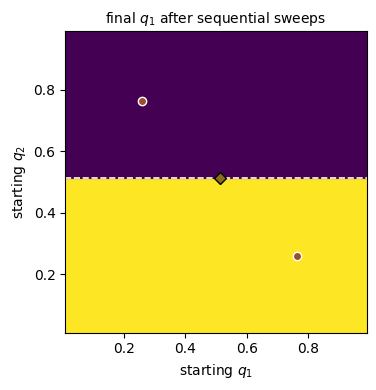

In [3]:
EXPECTED = {
    'cavi_sad_q': 0.5119402059903675,
    'cavi_lim_q1': 0.7626776215118606,
    'cavi_lim_q2': 0.2578574415109314,
    'cyc_lo': 0.2578574415109325,
    'cyc_hi': 0.7626776215118594,
    'cavi_lim_sweeps': 80.0,
}

P0, W, LK = 0.10, 0.90, 0.01
L00 = LK
L10 = 1.0 - (1.0 - W) * (1.0 - LK)
L11 = 1.0 - (1.0 - W) ** 2 * (1.0 - LK)
B0 = jnp.log(P0 / (1.0 - P0)) + jnp.log(L10 / L00)
B1 = jnp.log(L11 * L00 / L10 ** 2)

def R(q):                    # the coordinate update, in logistic form
    return jax.nn.sigmoid(B0 + B1 * q)

n_sweeps = int(EXPECTED['cavi_lim_sweeps'])

def run_seq(q0):
    def sweep(c, _):
        q1 = R(c[1])
        return jnp.array([q1, R(q1)]), None
    return jax.lax.scan(sweep, q0, None, length=n_sweeps)[0]

g = jnp.linspace(0.01, 0.99, 200)
Q1, Q2 = jnp.meshgrid(g, g, indexing='ij')
finals = jax.vmap(run_seq)(jnp.stack([Q1.ravel(), Q2.ravel()], -1)).reshape(200, 200, 2)
q_sad = EXPECTED['cavi_sad_q']
assert abs(float(R(q_sad)) - q_sad) < 1e-13
ends_high = np.asarray(finals[:, :, 0] > q_sad)
assert np.array_equal(ends_high, np.asarray(Q2 < q_sad)), 'basin boundary is not q2 = q_sad'
print(f'every start with q2 below {q_sad:.5f} ends with q1 high, every start above it with q1 low')
f0 = run_seq(jnp.array([0.10, 0.10]))
check('end point from (0.1, 0.1), q1', float(f0[0]), 'cavi_lim_q1', 1e-13)
check('end point from (0.1, 0.1), q2', float(f0[1]), 'cavi_lim_q2', 1e-13)

qj = jnp.array(0.10)
for _ in range(400):
    qj = R(qj)
cyc = sorted([float(qj), float(R(qj))])
check('simultaneous updates: two-cycle, lower', cyc[0], 'cyc_lo', 1e-12)
check('simultaneous updates: two-cycle, upper', cyc[1], 'cyc_hi', 1e-12)

fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.imshow(np.asarray(finals[:, :, 0]).T, origin='lower', extent=[0.01, 0.99, 0.01, 0.99], cmap='viridis')
ax.axhline(q_sad, color='white', ls='--', lw=1.2)
ax.plot([cyc[1], cyc[0]], [cyc[0], cyc[1]], 'o', color=COL['clay'], mec='white')
ax.plot([q_sad], [q_sad], 'D', color=COL['gold'], mec='black')
ax.set_xlabel(r'starting $q_1$')
ax.set_ylabel(r'starting $q_2$')
ax.set_title(r'final $q_1$ after sequential sweeps', fontsize=10)
plt.tight_layout()
plt.show()

## 3. Exponential and Gamma E-steps on all trials

The free energies of the Exponential product (parameters $\ln m_1, \ln m_2$) and the
Gamma product ($\ln m_1, \ln m_2, \ln k_1, \ln k_2$) are written once in JAX; their
gradients and Hessians come from `jax.grad` and `jax.hessian`, and are first checked
against the hand-derived formulas of Lesson 5 at random points.

The solver is the lesson's modified Newton method: Hessian eigenvalues replaced by
their absolute values and floored, steps capped at 2 per coordinate, the largest step
of the form $2^{-j}$ that satisfies the Armijo condition, and a stop when the largest
gradient component is below the tolerance or when no such step lowers $\mathcal{F}$
(the free energy has then reached its rounding level). For trials that stop the second
way, the code prints the decrease in $\mathcal{F}$ that one more Newton step would
predict. It is mapped over trials with `jax.vmap`,
started from the lesson's nine starting points, and the lowest free energy per trial
kept. Variational EM then runs from $(2.0, 0.5)$ with each E-step warm-started from
the previous $Q$, keeping the previous $Q$ on any trial where the new one is not lower,
and the code asserts that the total free energy never rises. The Gamma Hessian here
is exact, where the lesson's solver used central differences of the gradient. The two
notebooks share the free-energy formulas, so agreement of the fitted rates checks the
solvers against each other, not the formulas.

On Colab's free tier this section takes about three minutes, almost all of it in its second cell.

In [4]:
EXPECTED = {
    'tc_pin_exp_1': 2.071684971450819,
    'tc_pin_exp_2': 1.7108768625538346,
    'tc_pin_gam_1': 1.0378188619791473,
    'tc_pin_gam_2': 0.7991171886378986,
    'tc_fit_exp_1': 2.351874230594615,
    'tc_fit_exp_2': 1.8277360374526885,
    'tc_fit_gam_1': 1.0614944366330206,
    'tc_fit_gam_2': 0.8084203519015665,
    'tc_jt_gam_11': 0.22712399159371705,
    'tc_jt_gam_12': -0.11782084404130143,
    'tc_jt_gam_21': -0.06985539535301609,
    'tc_jt_gam_22': 0.18899293882103885,
    'tc_jt_exp_11': 0.42619068438005614,
    'tc_jt_exp_12': -0.32641678184395184,
    'tc_jt_exp_21': -0.2226191671825592,
    'tc_jt_exp_22': 0.3527540197009783,
}

def mulberry32(seed):
    a = [seed & 0xFFFFFFFF]
    def imul(x, y):
        return ((x & 0xFFFFFFFF) * (y & 0xFFFFFFFF)) & 0xFFFFFFFF
    def rnd():
        a[0] = (a[0] + 0x6D2B79F5) & 0xFFFFFFFF
        t = imul(a[0] ^ (a[0] >> 15), 1 | a[0])
        t = ((t + imul(t ^ (t >> 7), 61 | t)) & 0xFFFFFFFF) ^ t
        return ((t ^ (t >> 14)) & 0xFFFFFFFF) / 4294967296
    return rnd

def normal(r):
    a, b = r(), r()
    return sqrt(-2.0 * log(1.0 - a)) * cos(2.0 * pi * b)

r = mulberry32(42)
U1, U2 = np.empty(500), np.empty(500)
for n in range(500):
    s1 = -log(1.0 - r()) / 0.9
    s2 = -log(1.0 - r()) / 0.7
    U1[n] = s2 * s1 ** 2 + normal(r)
    U2[n] = s1 * s2 ** 2 + normal(r)
U1, U2 = jnp.asarray(U1), jnp.asarray(U2)
LN2PI = jnp.log(2 * jnp.pi)

def F_exp(x, u1, u2, r1, r2):
    a, b = x[0], x[1]
    return (-a - jnp.log(r1) + r1 * jnp.exp(a) - 1.0 - b - jnp.log(r2) + r2 * jnp.exp(b) - 1.0 + LN2PI
            + 0.5 * u1 ** 2 - 2.0 * u1 * jnp.exp(2 * a + b) + 24.0 * jnp.exp(4 * a + 2 * b)
            + 0.5 * u2 ** 2 - 2.0 * u2 * jnp.exp(a + 2 * b) + 24.0 * jnp.exp(2 * a + 4 * b))

def F_gam(x, u1, u2, r1, r2):
    m1, m2, k1, k2 = jnp.exp(x)
    c21, c22 = 1 + 1 / k1, 1 + 1 / k2
    c41, c42 = c21 * (1 + 2 / k1) * (1 + 3 / k1), c22 * (1 + 2 / k2) * (1 + 3 / k2)
    kl1 = -gammaln(k1) + (k1 - 1) * digamma(k1) + jnp.log(k1) - k1 - x[0] - jnp.log(r1) + r1 * m1
    kl2 = -gammaln(k2) + (k2 - 1) * digamma(k2) + jnp.log(k2) - k2 - x[1] - jnp.log(r2) + r2 * m2
    e1 = u1 ** 2 - 2 * u1 * m2 * m1 ** 2 * c21 + m2 ** 2 * c22 * m1 ** 4 * c41
    e2 = u2 ** 2 - 2 * u2 * m1 * m2 ** 2 * c22 + m1 ** 2 * c21 * m2 ** 4 * c42
    return kl1 + kl2 + LN2PI + 0.5 * e1 + 0.5 * e2

# the hand-derived gradient and Hessian of Lesson 5, in NumPy, for the check
def hand_exp(x, u1, u2, r1, r2):
    a, b = x
    A, B = np.exp(a), np.exp(b)
    E1, E2, E3, E4 = np.exp(2 * a + b), np.exp(4 * a + 2 * b), np.exp(a + 2 * b), np.exp(2 * a + 4 * b)
    g = np.array([-1 + r1 * A - 4 * u1 * E1 + 96 * E2 - 2 * u2 * E3 + 48 * E4,
                  -1 + r2 * B - 2 * u1 * E1 + 48 * E2 - 4 * u2 * E3 + 96 * E4])
    h12 = -4 * u1 * E1 + 192 * E2 - 4 * u2 * E3 + 192 * E4
    H = np.array([[r1 * A - 8 * u1 * E1 + 384 * E2 - 2 * u2 * E3 + 96 * E4, h12],
                  [h12, r2 * B - 2 * u1 * E1 + 96 * E2 - 8 * u2 * E3 + 384 * E4]])
    return g, H

def hand_gam(x, u1, u2, r1, r2):
    from scipy.special import polygamma
    m1, m2, k1, k2 = np.exp(x)
    c21, c22 = 1 + 1 / k1, 1 + 1 / k2
    c41, c42 = c21 * (1 + 2 / k1) * (1 + 3 / k1), c22 * (1 + 2 / k2) * (1 + 3 / k2)
    dc41 = -c41 * (1 / (k1 + 1) + 2 / (k1 + 2) + 3 / (k1 + 3))
    dc42 = -c42 * (1 / (k2 + 1) + 2 / (k2 + 2) + 3 / (k2 + 3))
    T1, Q1 = u1 * m2 * m1 ** 2 * c21, m2 ** 2 * c22 * m1 ** 4 * c41
    T2, Q2 = u2 * m1 * m2 ** 2 * c22, m1 ** 2 * c21 * m2 ** 4 * c42
    tg = lambda k: float(polygamma(1, k))
    return np.array([
        -1 + r1 * m1 - 2 * T1 + 2 * Q1 - T2 + Q2,
        -1 + r2 * m2 - T1 + Q1 - 2 * T2 + 2 * Q2,
        k1 * ((k1 - 1) * tg(k1) + 1 / k1 - 1) + T1 / (k1 * c21) + 0.5 * Q1 * dc41 / c41 - 0.5 * Q2 / (k1 * c21),
        k2 * ((k2 - 1) * tg(k2) + 1 / k2 - 1) - 0.5 * Q1 / (k2 * c22) + T2 / (k2 * c22) + 0.5 * Q2 * dc42 / c42])

rng = np.random.default_rng(1)
worst = [0.0, 0.0, 0.0]
for _ in range(20):
    x = rng.normal(size=4) * 0.5
    ua, ub = np.abs(rng.normal(size=2)) * 3
    g, H = hand_exp(x[:2], ua, ub, 0.9, 0.7)
    worst[0] = max(worst[0], np.max(np.abs(np.asarray(jax.grad(F_exp)(jnp.asarray(x[:2]), ua, ub, 0.9, 0.7)) - g) / (1 + np.abs(g))))
    worst[1] = max(worst[1], np.max(np.abs(np.asarray(jax.hessian(F_exp)(jnp.asarray(x[:2]), ua, ub, 0.9, 0.7)) - H) / (1 + np.abs(H))))
    gg = hand_gam(x, ua, ub, 0.9, 0.7)
    worst[2] = max(worst[2], np.max(np.abs(np.asarray(jax.grad(F_gam)(jnp.asarray(x), ua, ub, 0.9, 0.7)) - gg) / (1 + np.abs(gg))))
print('largest relative difference, hand against automatic: Exponential gradient {:.1e}, '
      'Exponential Hessian {:.1e}, Gamma gradient {:.1e}'.format(*worst))
assert max(worst) < 1e-12

largest relative difference, hand against automatic: Exponential gradient 4.1e-16, Exponential Hessian 2.2e-16, Gamma gradient 8.0e-16


In [5]:
def make_solver(F, tol, maxit=200):
    grad, hess = jax.grad(F), jax.hessian(F)
    ts = 2.0 ** -jnp.arange(60.0)

    def one(x, u1, u2, r1, r2):
        def cond(c):
            return ~c[1] & (c[2] < maxit)

        def body(c):
            x, done, i = c
            f = F(x, u1, u2, r1, r2)
            g, H = grad(x, u1, u2, r1, r2), hess(x, u1, u2, r1, r2)
            ev, V = jnp.linalg.eigh(0.5 * (H + H.T))
            evf = jnp.maximum(jnp.abs(ev), 1e-8 * jnp.maximum(1.0, jnp.max(jnp.abs(ev))))
            step = -V @ ((V.T @ g) / evf)
            dec = -g @ step
            step = step * jnp.minimum(1.0, 2.0 / jnp.maximum(jnp.max(jnp.abs(step)), 1e-300))
            fc = jax.vmap(lambda t: F(x + t * step, u1, u2, r1, r2))(ts)
            ok = fc <= f - 1e-4 * ts * dec
            done = (jnp.max(jnp.abs(g)) <= tol) | ~jnp.any(ok)
            return jnp.where(done, x, x + ts[jnp.argmax(ok)] * step), done, i + 1

        x = jax.lax.while_loop(cond, body, (x, False, 0))[0]
        return x, F(x, u1, u2, r1, r2), jnp.max(jnp.abs(grad(x, u1, u2, r1, r2)))

    return jax.jit(jax.vmap(one, in_axes=(0, 0, 0, None, None)))

solve_exp = make_solver(F_exp, 1e-10)
solve_gam = make_solver(F_gam, 1e-9)
EXP_STARTS = [(a, b) for a in (-2.0, 0.0, 1.5) for b in (-2.0, 0.0, 1.5)]
GAM_STARTS = [(a, a, k, k) for a in (-1.0, 0.0, 1.0) for k in (0.0, 2.0, 5.0)]

def multistart(solve, starts, lam):
    best_x = best_f = None
    for s in starts:
        x0 = jnp.tile(jnp.asarray(s), (500, 1))
        x, f, _ = solve(x0, U1, U2, lam[0], lam[1])
        if best_x is None:
            best_x, best_f = x, f
        else:
            better = f < best_f
            best_x = jnp.where(better[:, None], x, best_x)
            best_f = jnp.where(better, f, best_f)
    return best_x, best_f

def variational_em(solve, F, starts, lam0=(2.0, 0.5), tol=1e-11, maxit=3000):
    Fv = jax.vmap(F, in_axes=(0, 0, 0, None, None))
    lam = jnp.asarray(lam0)
    x, f = multistart(solve, starts, lam)
    Ftot = [float(f.sum())]
    for it in range(1, maxit + 1):
        new = 1 / jnp.exp(x[:, :2]).mean(axis=0)               # the M-step
        f_m = Fv(x, U1, U2, new[0], new[1])                     # old Q, new rates
        assert float(f_m.sum()) <= Ftot[-1] + 1e-10 * abs(Ftot[-1]), 'M-step raised F'
        x_new, f_new, _ = solve(x, U1, U2, new[0], new[1])     # warm-started E-step
        keep = f_new > f_m
        x = jnp.where(keep[:, None], x, x_new)
        f = jnp.where(keep, f_m, f_new)
        assert float(f.sum()) <= float(f_m.sum()) + 1e-10 * abs(float(f_m.sum())), 'E-step raised F'
        Ftot.append(float(f.sum()))
        done = float(jnp.max(jnp.abs(new - lam) / new)) < tol
        lam = new
        if done:
            return lam, it, np.array(Ftot), x
    raise RuntimeError('EM did not converge')

for name, solve, F, starts in (('exp', solve_exp, F_exp, EXP_STARTS), ('gam', solve_gam, F_gam, GAM_STARTS)):
    t0 = perf_counter()
    x, f = multistart(solve, starts, (0.9, 0.7))
    pin = 1 / jnp.exp(x[:, :2]).mean(axis=0)
    check(f'{name}: one-step rate 1', float(pin[0]), f'tc_pin_{name}_1', 1e-8)
    check(f'{name}: one-step rate 2', float(pin[1]), f'tc_pin_{name}_2', 1e-8)
    # the M-map Jacobian at the true rates from the implicit-function formula, with the
    # exact automatic Hessian of each trial's free energy
    Hp = jax.vmap(jax.hessian(F), in_axes=(0, 0, 0, None, None))(x, U1, U2, 0.9, 0.7)
    m = jnp.exp(x[:, :2])
    hv = jnp.zeros((500, x.shape[1], 2)).at[:, 0, 0].set(m[:, 0]).at[:, 1, 1].set(m[:, 1])
    Jt = np.asarray(jnp.einsum('nki,nkj->ij', hv, jnp.linalg.solve(Hp, hv)) / 500 / m.mean(axis=0)[:, None] ** 2)
    print(f'{name}: J at the true rates from the exact Hessian:', Jt.round(8).tolist())
    for i in range(2):
        for j in range(2):
            check(f'{name}: J[{i + 1}{j + 1}]', Jt[i, j], f'tc_jt_{name}_{i + 1}{j + 1}', 1e-6)
    lam, its, Ftot, x = variational_em(solve, F, starts)
    g = jax.vmap(jax.grad(F), in_axes=(0, 0, 0, None, None))(x, U1, U2, lam[0], lam[1])
    H = jax.vmap(jax.hessian(F), in_axes=(0, 0, 0, None, None))(x, U1, U2, lam[0], lam[1])
    ev, V = jnp.linalg.eigh(H)
    pred = 0.5 * jnp.sum((jnp.einsum('nji,nj->ni', V, g)) ** 2 / jnp.abs(ev), axis=1)
    gmax = jnp.max(jnp.abs(g), axis=1)
    tol = 1e-10 if name == 'exp' else 1e-9
    print(f'{name}: fitted ({float(lam[0]):.6f}, {float(lam[1]):.6f}) after {its} iterations, '
          f'{perf_counter() - t0:.1f} s')
    print(f'    last E-step: largest gradient component {float(gmax.max()):.1e}, {int((gmax > tol).sum())} '
          f'trials above {tol:.0e}; largest decrease a further Newton step predicts {float(pred.max()):.1e} nats')
    check(f'{name}: fitted rate 1', float(lam[0]), f'tc_fit_{name}_1', 1e-7)
    check(f'{name}: fitted rate 2', float(lam[1]), f'tc_fit_{name}_2', 1e-7)

ok       exp: one-step rate 1                    2.071684971   lesson  2.071684971
ok       exp: one-step rate 2                    1.710876862   lesson  1.710876863


exp: J at the true rates from the exact Hessian: [[0.42619068, -0.32641678], [-0.22261917, 0.35275402]]
ok       exp: J[11]                              0.4261906843   lesson  0.4261906844
ok       exp: J[12]                             -0.3264167818   lesson -0.3264167818
ok       exp: J[21]                             -0.2226191671   lesson -0.2226191672
ok       exp: J[22]                              0.3527540196   lesson  0.3527540197


exp: fitted (2.351874, 1.827736) after 46 iterations, 4.4 s
    last E-step: largest gradient component 9.2e-09, 10 trials above 1e-10; largest decrease a further Newton step predicts 7.1e-17 nats
ok       exp: fitted rate 1                      2.351874231   lesson  2.351874231
ok       exp: fitted rate 2                      1.827736037   lesson  1.827736037


ok       gam: one-step rate 1                    1.037818862   lesson  1.037818862
ok       gam: one-step rate 2                    0.7991171885   lesson  0.7991171886


gam: J at the true rates from the exact Hessian: [[0.22712399, -0.11782084], [-0.0698554, 0.18899294]]
ok       gam: J[11]                              0.2271239912   lesson  0.2271239916
ok       gam: J[12]                             -0.1178208439   lesson -0.117820844
ok       gam: J[21]                             -0.06985539528   lesson -0.06985539535
ok       gam: J[22]                              0.1889929385   lesson  0.1889929388


gam: fitted (1.061494, 0.808420) after 56 iterations, 15.2 s
    last E-step: largest gradient component 2.9e-04, 340 trials above 1e-09; largest decrease a further Newton step predicts 4.1e-12 nats
ok       gam: fitted rate 1                      1.061494456   lesson  1.061494437
ok       gam: fitted rate 2                      0.8084203351   lesson  0.8084203519
